# Experiment 049: GPT-2 XL final symmetry package

12 completed MC-SFT endpoints and records the 3 direct base GRPO A1 outcomes. The log probability probe is the primary tool. Generated accuracy is interpreted only when the registered extraction coverage guard passes.

The Qwen2.5 1.5B panels are descriptive context. They compare complete pretrained model bundles, not an isolated architecture effect.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'config.py').exists(), 'run this notebook from the code repository'
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from scripts.s12_eval import atomic_write_json, sha256

RESULTS = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '049_1'
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1, 2)
TIERS = ('overall', 'hard')
PREFLIGHT = RESULTS / '049_technical' / '049_preflight.json'
LAUNCH = RESULTS / '049_technical' / '049_launch.json'

FAMILIES = {
    'p2': {'label': 'p2', 'steps': 31,
           'tag': '049_p2_COLAB_FULL_GPT2_B15_sft_only_seed{seed}'},
    'p8': {'label': 'p8', 'steps': 123,
           'tag': '049_p8_COLAB_FULL_GPT2_B15_sft_only_seed{seed}'},
    'p32': {'label': 'p32', 'steps': 490,
            'tag': '049_p32_COLAB_FULL_GPT2_B15_sft_only_seed{seed}'},
    'wsft_p8': {'label': 'warm p8', 'steps': 123,
                'tag': '049_wsft_p8_COLAB_FULL_GPT2_B15_sft_only_seed{seed}'},
}
PAIR_SPECS = {
    'F1': ('base', 'p8', 'base to p8'),
    'F2a': ('p2', 'p8', 'p2 to p8'),
    'F2b': ('p8', 'p32', 'p8 to p32'),
    'F3': ('p8', 'wsft_p8', 'plain p8 to warm p8'),
}
QWEN_TAGS = {
    'p2': '010_p2_COLAB_FULL_B15_sft_only_seed{seed}',
    'p8': '010_p8_COLAB_FULL_B15_sft_only_seed{seed}',
    'p32': '010_p32_COLAB_FULL_B15_sft_only_seed{seed}',
    'wsft_p8': '011_wsft_COLAB_FULL_B15_sft_only_seed{seed}',
}
COLORS = {'base': '#9C9C9C', 'p2': '#4C78A8', 'p8': '#59A14F',
          'p32': '#F28E2B', 'wsft_p8': '#B279A2'}

def read_json(path):
    with open(path) as handle:
        return json.load(handle)

def read_rows(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def coverage(rows):
    return float(np.mean([row.get('pred') is not None for row in rows]))

def aligned(left, right):
    left, right = align_pred_rows(left, right)
    assert len(left) == len(right) == 1884
    assert [(row['subject'], row['tier'], row['gold']) for row in left] == [
        (row['subject'], row['tier'], row['gold']) for row in right]
    return left, right

def category(delta, low, high, adjusted_p):
    if low > -.02 and high < .02:
        return 'equivalent'
    if delta >= .02 and adjusted_p < .05:
        return 'gain'
    if delta <= -.02 and adjusted_p < .05:
        return 'decline'
    return 'inconclusive'

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

## Completion and integrity

All result values are read only after the committed record chain is rechecked. Local copy doesn't contain the large Drive checkpoints, so nb verifies the preflight digest, training logs, endpoint manifests, prediction files, terminal records that were committed from those checkpoints.

In [2]:
preflight = read_json(PREFLIGHT)
launch = read_json(LAUNCH)
assert preflight['completed'] is True and preflight['experiment'] == '049'
assert launch['completed'] is True and launch['experiment'] == '049'
assert launch['preflight_sha256'] == sha256(str(PREFLIGHT))
assert launch['roster'] == preflight['roster'] and len(launch['roster']) == 15

source_hashes = {
    '049_preflight.json': sha256(str(PREFLIGHT)),
    '049_launch.json': sha256(str(LAUNCH)),
}
runs = {}
health_rows = []

# verify each supervised arm through its write last completion record
for family, spec in FAMILIES.items():
    runs[family] = {}
    for seed in SEEDS:
        tag = spec['tag'].format(seed=seed)
        result_dir = RESULTS / tag
        complete_path = result_dir / '049_arm_complete.json'
        training_path = result_dir / '049_sft_training.json'
        endpoint_path = result_dir / '049_sft_eval_manifest.json'
        complete = read_json(complete_path)
        training = read_json(training_path)
        endpoint = read_json(endpoint_path)
        assert complete['completed'] is True and complete['experiment'] == '049'
        assert complete['family'] == family and complete['seed'] == seed
        assert complete['preflight_sha256'] == sha256(str(PREFLIGHT))
        assert complete['sha256'] == {
            '049_sft_training.json': sha256(str(training_path)),
            '049_sft_eval_manifest.json': sha256(str(endpoint_path)),
        }
        assert training['completed'] is True and training['family'] == family
        assert training['seed'] == seed and training['updates'] == spec['steps']
        assert training['trainlog_sha256'] == sha256(str(result_dir / 'sft_trainlog.json'))
        assert endpoint['completed'] is True and endpoint['binding'] == training
        for name, digest in endpoint['sha256'].items():
            assert sha256(str(result_dir / name)) == digest
        generated = read_rows(result_dir / 'sft_preds.jsonl')
        probe = read_rows(result_dir / 'sft_logprob_preds.jsonl')
        aligned(generated, probe)
        assert len(generated) == len(probe) == 1884
        runs[family][seed] = {
            'generated': generated,
            'probe': probe,
            'eval': read_json(result_dir / 'sft_eval.json'),
            'probe_eval': read_json(result_dir / 'sft_logprob.json'),
            'trainlog': read_json(result_dir / 'sft_trainlog.json'),
            'training': training,
        }
        source_hashes[tag] = sha256(str(complete_path))
        health_rows.append({'family': spec['label'], 'seed': seed,
                            'state': 'committed', 'endpoint rows': len(generated),
                            'updates': training['updates']})

base_dir = RESULTS / '046_COLAB_FULL_GPT2_B15_base'
base_manifest_path = base_dir / '046_base_eval_manifest.json'
base_manifest = read_json(base_manifest_path)
assert base_manifest['completed'] is True and base_manifest['branch'] == 'base'
for name, digest in base_manifest['sha256'].items():
    assert sha256(str(base_dir / name)) == digest
base = {
    'generated': read_rows(base_dir / 'base_preds.jsonl'),
    'probe': read_rows(base_dir / 'base_logprob_preds.jsonl'),
    'eval': read_json(base_dir / 'base_eval.json'),
    'probe_eval': read_json(base_dir / 'base_logprob.json'),
}
aligned(base['generated'], base['probe'])
source_hashes['046_COLAB_FULL_GPT2_B15_base'] = sha256(str(base_manifest_path))

a1_rows = []
for seed in SEEDS:
    tag = f'049_base_grpo_COLAB_FULL_GPT2_B15_base_grpo_seed{seed}'
    result_dir = RESULTS / tag
    record_path = result_dir / '049_a1_conclusion.json'
    status_path = result_dir / 'grpo_worker_status.json'
    record = read_json(record_path)
    status = read_json(status_path)
    assert record['completed'] is True and record['outcome'] == 'a1'
    assert record['experiment'] == '049' and record['family'] == 'base_grpo'
    assert record['seed'] == seed and record['status_sha256'] == sha256(str(status_path))
    assert status['completed'] is False and status['task'] == 'grpo'
    assert status['family'] == 'base_grpo' and status['seed'] == seed
    assert status['cuda_oom'] is False and 'sentinel abort: a1' in status['error_message']
    for forbidden in ('049_grpo_training.json', '049_grpo_eval_manifest.json',
                      '049_arm_complete.json'):
        assert not (result_dir / forbidden).exists()
    source_hashes[tag] = sha256(str(record_path))
    a1_rows.append({'seed': seed, 'outcome': 'A1 truncation stop',
                    'decision update': 50,
                    'wall minutes': status['wall_seconds'] / 60,
                    'peak reserved GiB': status['peak_reserved_gib'],
                    'OOM': status['cuda_oom']})
    health_rows.append({'family': 'base GRPO', 'seed': seed,
                        'state': 'A1 terminal', 'endpoint rows': 0,
                        'updates': 50})

health_df = pd.DataFrame(health_rows)
assert len(health_df) == 15
display(health_df)

,family,seed,state,endpoint rows,updates
0,p2,0,committed,1884,31
1,p2,1,committed,1884,31
2,p2,2,committed,1884,31
3,p8,0,committed,1884,123
4,p8,1,committed,1884,123
5,p8,2,committed,1884,123
6,p32,0,committed,1884,490
7,p32,1,committed,1884,490
8,p32,2,committed,1884,490
9,warm p8,0,committed,1884,123


## Endpoint summary

Exposure arms have learnt the requested answer format. The primary question is whether that surface fit also changed the format independent answer probe.

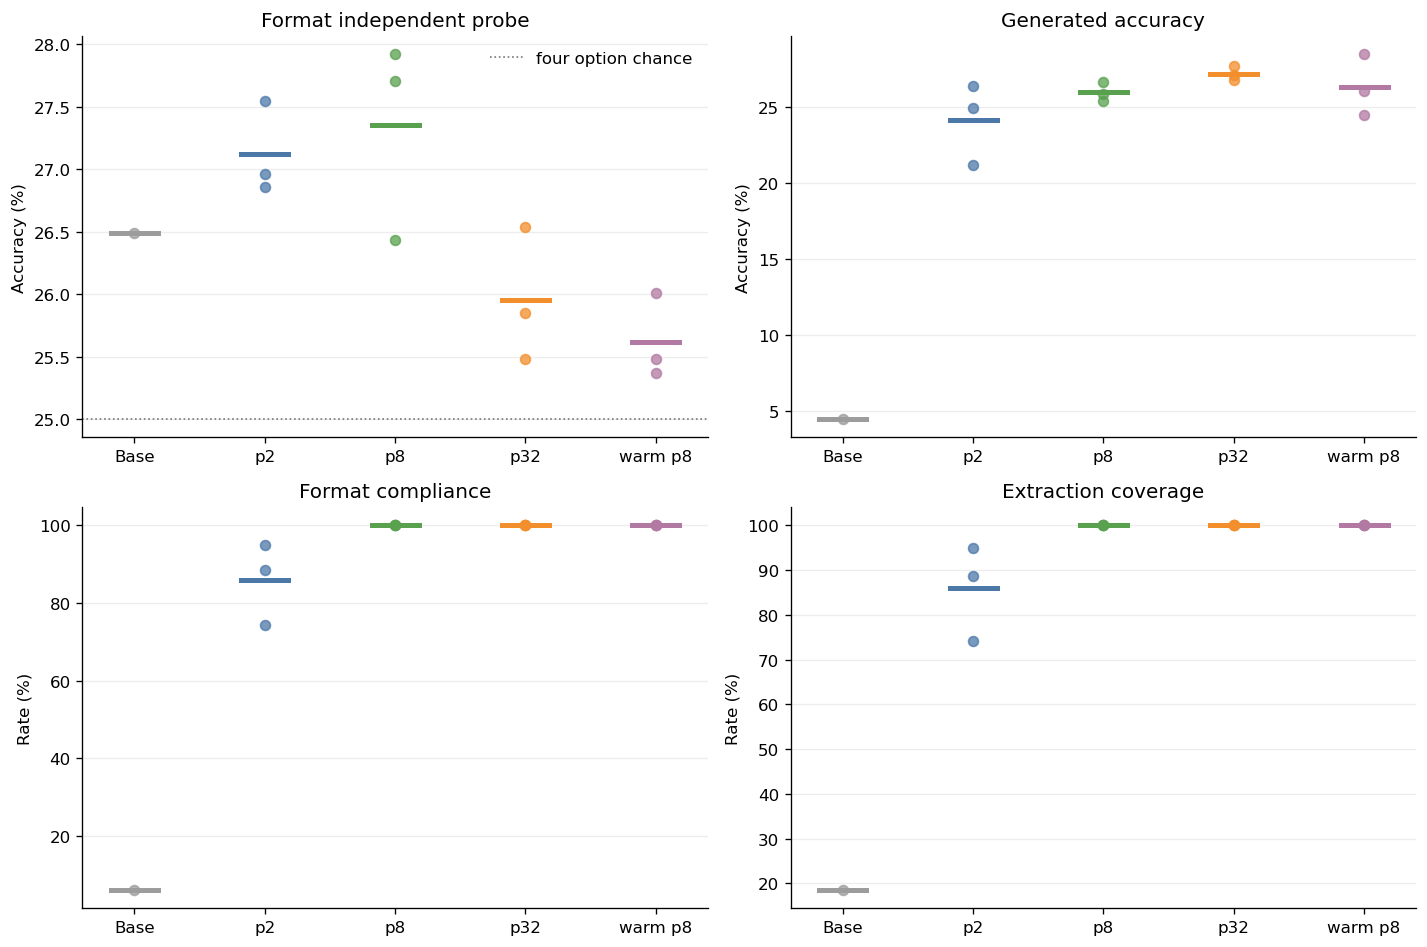

,family,label,seeds,generated_accuracy,generated_min,generated_max,probe_accuracy,probe_min,probe_max,format_compliance,extraction_coverage,mean_length
0,base,Base,1,0.0446,0.0446,0.0446,0.2649,0.2649,0.2649,0.0610,0.1852,208.4496
1,p2,p2,3,0.2419,0.2123,0.2638,0.2712,0.2686,0.2755,0.8593,0.8593,16.8719
2,p8,p8,3,0.2601,0.2542,0.2670,0.2735,0.2643,0.2792,1.0000,1.0000,18.0000
3,p32,p32,3,0.2721,0.2680,0.2771,0.2596,0.2548,0.2654,1.0000,1.0000,18.0000
4,wsft_p8,warm p8,3,0.2634,0.2447,0.2850,0.2562,0.2537,0.2601,1.0000,1.0000,18.0000


In [3]:
endpoint_rows = [{
    'family': 'base', 'label': 'Base', 'seed': -1,
    'generated accuracy': accuracy(base['generated']),
    'probe accuracy': accuracy(base['probe']),
    'format compliance': base['eval']['format_compliance'],
    'extraction coverage': coverage(base['generated']),
    'mean length': base['eval']['mean_len'],
}]
for family, spec in FAMILIES.items():
    for seed in SEEDS:
        run = runs[family][seed]
        endpoint_rows.append({
            'family': family, 'label': spec['label'], 'seed': seed,
            'generated accuracy': accuracy(run['generated']),
            'probe accuracy': accuracy(run['probe']),
            'format compliance': run['eval']['format_compliance'],
            'extraction coverage': coverage(run['generated']),
            'mean length': run['eval']['mean_len'],
        })
endpoint_df = pd.DataFrame(endpoint_rows)
endpoint_summary = endpoint_df.groupby(['family', 'label'], sort=False).agg(
    seeds=('seed', 'count'),
    generated_accuracy=('generated accuracy', 'mean'),
    generated_min=('generated accuracy', 'min'),
    generated_max=('generated accuracy', 'max'),
    probe_accuracy=('probe accuracy', 'mean'),
    probe_min=('probe accuracy', 'min'),
    probe_max=('probe accuracy', 'max'),
    format_compliance=('format compliance', 'mean'),
    extraction_coverage=('extraction coverage', 'mean'),
    mean_length=('mean length', 'mean'),
).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
metrics = (
    ('probe accuracy', 'Format independent probe', 'Accuracy (%)'),
    ('generated accuracy', 'Generated accuracy', 'Accuracy (%)'),
    ('format compliance', 'Format compliance', 'Rate (%)'),
    ('extraction coverage', 'Extraction coverage', 'Rate (%)'),
)
order = ['base', 'p2', 'p8', 'p32', 'wsft_p8']
labels = ['Base', 'p2', 'p8', 'p32', 'warm p8']
for ax, (metric, title, ylabel) in zip(axes.flat, metrics):
    for x, family in enumerate(order):
        values = endpoint_df.loc[endpoint_df.family == family, metric] * 100
        ax.scatter(np.full(len(values), x), values, s=35,
                   color=COLORS[family], alpha=.75, zorder=3)
        ax.plot([x - .18, x + .18], [values.mean(), values.mean()],
                color=COLORS[family], linewidth=3)
    ax.set_xticks(range(len(order)), labels)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y', alpha=.22)
axes[0, 0].axhline(25, color='#777777', linestyle=':', linewidth=1,
                   label='four option chance')
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig01_endpoint_summary.png', bbox_inches='tight')
plt.show()
display(endpoint_summary.style.format(precision=4))

## Registered probe families

Each family uses the fixed 3 seed combination. Holm correction is applied across 3 seed comparisons, separately for overall and hard tier results. Equivalence requires the whole paired 95% interval to be inside the fixed plus or minus 2 point band.

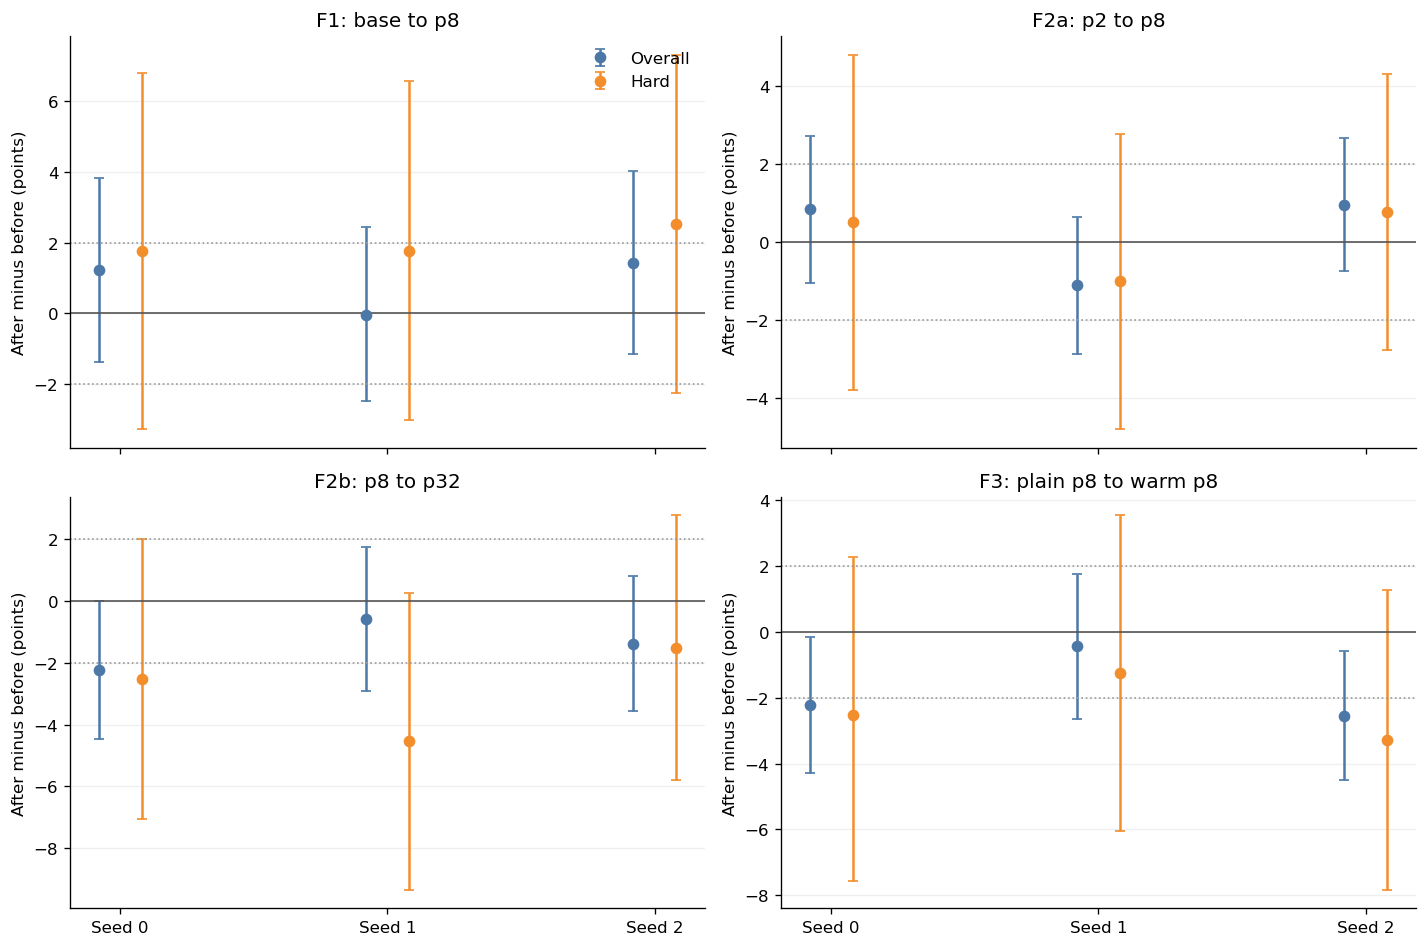

,family,comparison,tier,seed,n,before,after,delta,CI low,CI high,raw p,gains,losses,Holm p,category
0,F1,base to p8,overall,0,1884,0.2649,0.2771,+0.0122,-0.0138,+0.0382,0.3796,325,302,0.8810,inconclusive
1,F1,base to p8,overall,1,1884,0.2649,0.2643,-0.0005,-0.0249,+0.0244,1.0000,284,285,1.0000,inconclusive
2,F1,base to p8,overall,2,1884,0.2649,0.2792,+0.0143,-0.0117,+0.0403,0.2937,320,293,0.8810,inconclusive
3,F1,base to p8,hard,0,396,0.2652,0.2828,+0.0177,-0.0328,+0.0682,0.5546,55,48,1.0000,inconclusive
4,F1,base to p8,hard,1,396,0.2652,0.2828,+0.0177,-0.0303,+0.0657,0.5384,51,44,1.0000,inconclusive
5,F1,base to p8,hard,2,396,0.2652,0.2904,+0.0253,-0.0227,+0.0732,0.3533,52,42,1.0000,inconclusive
6,F2a,p2 to p8,overall,0,1884,0.2686,0.2771,+0.0085,-0.0106,+0.0271,0.4061,171,155,0.7229,inconclusive
7,F2a,p2 to p8,overall,1,1884,0.2755,0.2643,-0.0111,-0.0287,+0.0064,0.2410,135,156,0.7229,inconclusive
8,F2a,p2 to p8,overall,2,1884,0.2696,0.2792,+0.0096,-0.0074,+0.0265,0.3026,145,127,0.7229,inconclusive
9,F2a,p2 to p8,hard,0,396,0.2778,0.2828,+0.0051,-0.0379,+0.0480,0.9063,37,35,1.0000,inconclusive


,family,comparison,tier,seed categories,common reading,mean delta,range low,range high
0,F1,base to p8,overall,"inconclusive, inconclusive, inconclusive",no common reading,+0.0087,-0.0005,+0.0143
1,F1,base to p8,hard,"inconclusive, inconclusive, inconclusive",no common reading,+0.0202,+0.0177,+0.0253
2,F2a,p2 to p8,overall,"inconclusive, inconclusive, inconclusive",no common reading,+0.0023,-0.0111,+0.0096
3,F2a,p2 to p8,hard,"inconclusive, inconclusive, inconclusive",no common reading,+0.0008,-0.0101,+0.0076
4,F2b,p8 to p32,overall,"inconclusive, inconclusive, inconclusive",no common reading,-0.0140,-0.0223,-0.0058
5,F2b,p8 to p32,hard,"inconclusive, inconclusive, inconclusive",no common reading,-0.0286,-0.0455,-0.0152
6,F3,plain p8 to warm p8,overall,"inconclusive, inconclusive, decline",no common reading,-0.0173,-0.0255,-0.0042
7,F3,plain p8 to warm p8,hard,"inconclusive, inconclusive, inconclusive",no common reading,-0.0236,-0.0328,-0.0126


In [4]:
def endpoint(family, seed, instrument):
    if family == 'base':
        return base[instrument]
    return runs[family][seed][instrument]

comparison_rows = []
for family, (before_name, after_name, label) in PAIR_SPECS.items():
    for tier in TIERS:
        family_rows = []
        for seed in SEEDS:
            before_rows, after_rows = aligned(
                endpoint(before_name, seed, 'probe'),
                endpoint(after_name, seed, 'probe'))
            if tier == 'hard':
                pairs = [(left, right) for left, right in zip(before_rows, after_rows)
                         if left['tier'] == 'hard']
            else:
                pairs = list(zip(before_rows, after_rows))
            before = [bool(left['correct']) for left, _ in pairs]
            after = [bool(right['correct']) for _, right in pairs]
            delta, low, high = paired_delta_ci(
                before, after, n_boot=10000,
                seed=49000 + 100 * list(PAIR_SPECS).index(family)
                     + 10 * list(TIERS).index(tier) + seed)
            gains = sum(not left and right for left, right in zip(before, after))
            losses = sum(left and not right for left, right in zip(before, after))
            family_rows.append({
                'family': family, 'comparison': label, 'tier': tier, 'seed': seed,
                'n': len(before), 'before': float(np.mean(before)),
                'after': float(np.mean(after)), 'delta': delta,
                'CI low': low, 'CI high': high,
                'raw p': mcnemar_exact(gains, losses),
                'gains': gains, 'losses': losses,
            })
        adjusted = holm([row['raw p'] for row in family_rows])
        for row, adjusted_p in zip(family_rows, adjusted):
            row['Holm p'] = adjusted_p
            row['category'] = category(
                row['delta'], row['CI low'], row['CI high'], adjusted_p)
            comparison_rows.append(row)

comparison_df = pd.DataFrame(comparison_rows)
common_rows = []
for family, (before_name, after_name, label) in PAIR_SPECS.items():
    for tier in TIERS:
        values = comparison_df[
            (comparison_df.family == family) & (comparison_df.tier == tier)]
        categories = values.sort_values('seed').category.tolist()
        common = categories[0] if len(set(categories)) == 1                  and categories[0] != 'inconclusive' else 'no common reading'
        common_rows.append({'family': family, 'comparison': label, 'tier': tier,
                            'seed categories': ', '.join(categories),
                            'common reading': common,
                            'mean delta': values.delta.mean(),
                            'range low': values.delta.min(),
                            'range high': values.delta.max()})
common_df = pd.DataFrame(common_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, (family, (_, _, label)) in zip(axes.flat, PAIR_SPECS.items()):
    frame = comparison_df[comparison_df.family == family]
    for tier, colour, offset in (('overall', '#4C78A8', -.08),
                                 ('hard', '#F28E2B', .08)):
        rows = frame[frame.tier == tier].sort_values('seed')
        x = rows.seed.to_numpy(dtype=float) + offset
        y = rows.delta.to_numpy() * 100
        yerr = np.vstack((y - rows['CI low'].to_numpy() * 100,
                          rows['CI high'].to_numpy() * 100 - y))
        ax.errorbar(x, y, yerr=yerr, fmt='o', capsize=3,
                    color=colour, label=tier.title())
    ax.axhline(0, color='#555555', linewidth=1)
    ax.axhline(-2, color='#999999', linestyle=':', linewidth=1)
    ax.axhline(2, color='#999999', linestyle=':', linewidth=1)
    ax.set_xticks(SEEDS, [f'Seed {seed}' for seed in SEEDS])
    ax.set_ylabel('After minus before (points)')
    ax.set_title(f'{family}: {label}')
    ax.grid(axis='y', alpha=.2)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig02_registered_probe_changes.png', bbox_inches='tight')
plt.show()
display(comparison_df.style.format({
    'before': '{:.4f}', 'after': '{:.4f}', 'delta': '{:+.4f}',
    'CI low': '{:+.4f}', 'CI high': '{:+.4f}',
    'raw p': '{:.4f}', 'Holm p': '{:.4f}',
}))
display(common_df.style.format({
    'mean delta': '{:+.4f}', 'range low': '{:+.4f}',
    'range high': '{:+.4f}',
}))

## Generated endpoint guard

Generated accuracy. A knowledge reading is allowed only when both endpoints have at least 50% extraction coverage and their coverage differs no more than 2 points.

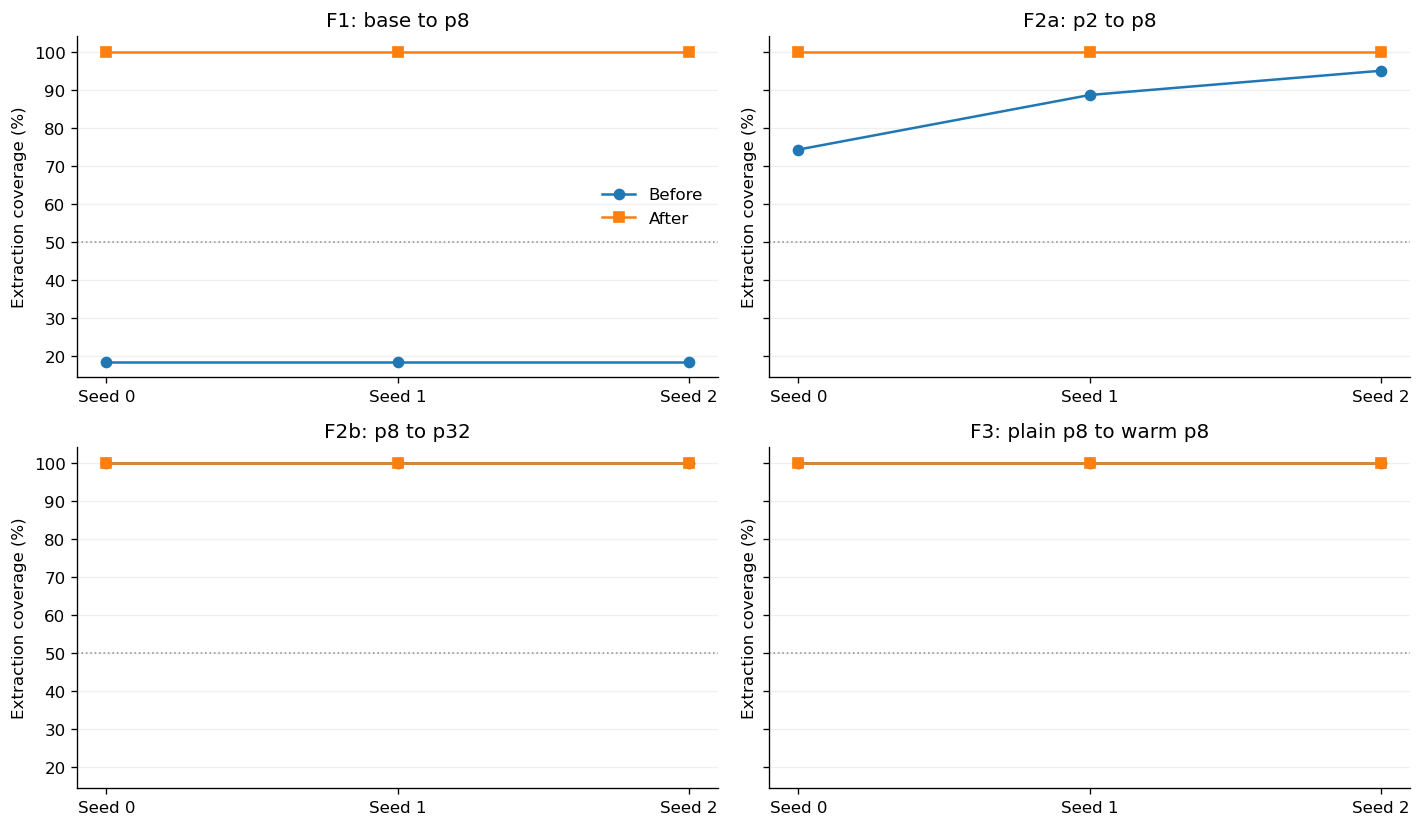

,family,comparison,seed,before coverage,after coverage,coverage change,guard passes,joint rows,joint delta,joint CI low,joint CI high,reading
0,F1,base to p8,0,0.1852,1.0000,+0.8148,False,349,-0.0057,-0.0716,+0.0602,instrument limited
1,F1,base to p8,1,0.1852,1.0000,+0.8148,False,349,+0.0057,-0.0602,+0.0745,instrument limited
2,F1,base to p8,2,0.1852,1.0000,+0.8148,False,349,+0.0029,-0.0602,+0.0659,instrument limited
3,F2a,p2 to p8,0,0.7426,1.0000,+0.2574,False,1399,-0.0157,-0.0486,+0.0164,instrument limited
4,F2a,p2 to p8,1,0.8859,1.0000,+0.1141,False,1669,-0.0174,-0.0443,+0.0102,instrument limited
5,F2a,p2 to p8,2,0.9496,1.0000,+0.0504,False,1789,-0.0196,-0.0481,+0.0089,instrument limited
6,F2b,p8 to p32,0,1.0000,1.0000,+0.0000,True,1884,+0.0011,-0.0250,+0.0276,descriptive
7,F2b,p8 to p32,1,1.0000,1.0000,+0.0000,True,1884,+0.0180,-0.0064,+0.0430,descriptive
8,F2b,p8 to p32,2,1.0000,1.0000,+0.0000,True,1884,+0.0170,-0.0074,+0.0414,descriptive
9,F3,plain p8 to warm p8,0,1.0000,1.0000,+0.0000,True,1884,-0.0223,-0.0441,-0.0011,descriptive


In [5]:
guard_rows = []
for family, (before_name, after_name, label) in PAIR_SPECS.items():
    for seed in SEEDS:
        before_rows, after_rows = aligned(
            endpoint(before_name, seed, 'generated'),
            endpoint(after_name, seed, 'generated'))
        before_coverage = coverage(before_rows)
        after_coverage = coverage(after_rows)
        guard = (min(before_coverage, after_coverage) >= .5
                 and abs(after_coverage - before_coverage) <= .02)
        joint = [(left, right) for left, right in zip(before_rows, after_rows)
                 if left.get('pred') is not None and right.get('pred') is not None]
        before_joint = [bool(left['correct']) for left, _ in joint]
        after_joint = [bool(right['correct']) for _, right in joint]
        delta, low, high = paired_delta_ci(
            before_joint, after_joint, n_boot=10000,
            seed=59000 + 100 * list(PAIR_SPECS).index(family) + seed)
        guard_rows.append({
            'family': family, 'comparison': label, 'seed': seed,
            'before coverage': before_coverage,
            'after coverage': after_coverage,
            'coverage change': after_coverage - before_coverage,
            'guard passes': guard, 'joint rows': len(joint),
            'joint delta': delta, 'joint CI low': low, 'joint CI high': high,
            'reading': 'descriptive' if guard else 'instrument limited',
        })
guard_df = pd.DataFrame(guard_rows)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharey=True)
for ax, (family, (_, _, label)) in zip(axes.flat, PAIR_SPECS.items()):
    frame = guard_df[guard_df.family == family].sort_values('seed')
    x = np.arange(len(frame))
    ax.plot(x, frame['before coverage'] * 100, marker='o', label='Before')
    ax.plot(x, frame['after coverage'] * 100, marker='s', label='After')
    ax.axhline(50, color='#999999', linestyle=':', linewidth=1)
    ax.set_xticks(x, [f'Seed {seed}' for seed in frame.seed])
    ax.set_ylabel('Extraction coverage (%)')
    ax.set_title(f'{family}: {label}')
    ax.grid(axis='y', alpha=.2)
axes[0, 0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig03_generated_coverage_guards.png', bbox_inches='tight')
plt.show()
display(guard_df.style.format({
    'before coverage': '{:.4f}', 'after coverage': '{:.4f}',
    'coverage change': '{:+.4f}', 'joint delta': '{:+.4f}',
    'joint CI low': '{:+.4f}', 'joint CI high': '{:+.4f}',
}))

## Training fit

Supervised loss and token accuracy show whether each exposure schedule fitted training rows. This is descriptive process evidence and doesn't replace held out MMLU evaluation.

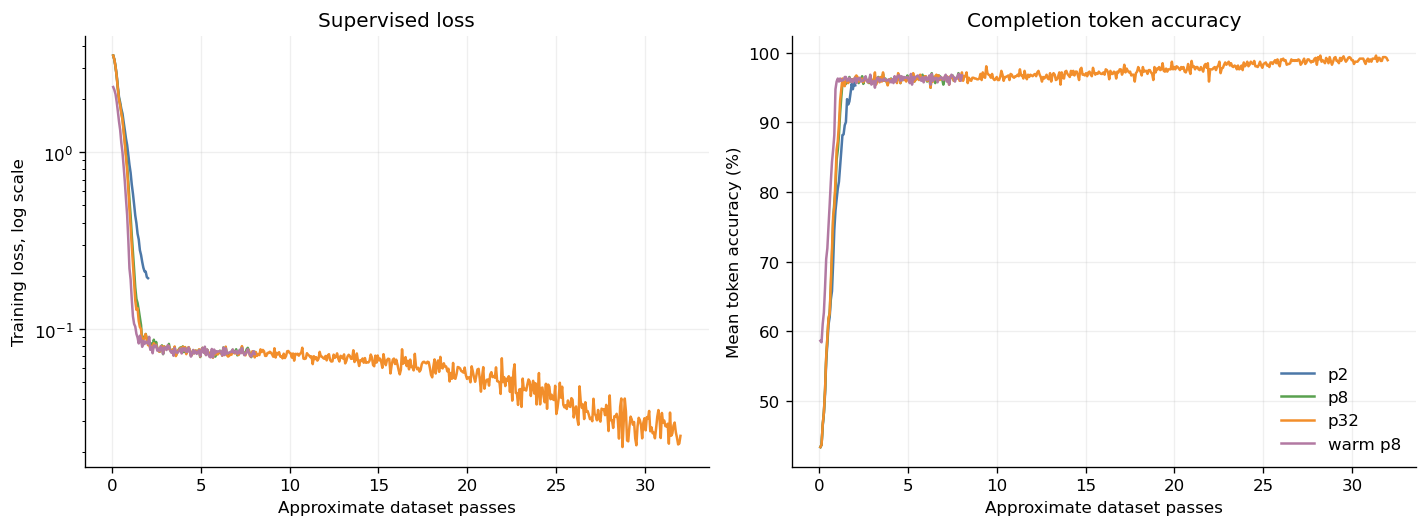

,family,label,seed,updates,passes,initial loss,final loss,initial token accuracy,final token accuracy
0,p2,p2,0,31,2.0245,3.5336,0.1948,0.4243,0.9507
1,p2,p2,1,31,2.0245,3.4892,0.1936,0.4572,0.9605
2,p2,p2,2,31,2.0245,3.5582,0.1932,0.4211,0.9474
3,p8,p8,0,123,8.0327,3.5336,0.0751,0.4243,0.9671
4,p8,p8,1,123,8.0327,3.4892,0.0747,0.4572,0.9671
5,p8,p8,2,123,8.0327,3.5582,0.0726,0.4211,0.9638
6,p32,p32,0,490,32.0000,3.5336,0.0267,0.4243,0.9901
7,p32,p32,1,490,32.0000,3.4892,0.0186,0.4572,0.9901
8,p32,p32,2,490,32.0000,3.5582,0.0292,0.4211,0.9868
9,wsft_p8,warm p8,0,123,8.0327,2.3374,0.0731,0.5954,0.9737


In [6]:
training_rows = []
training_summary_rows = []
for family, spec in FAMILIES.items():
    for seed in SEEDS:
        frame = pd.DataFrame(runs[family][seed]['trainlog'])
        frame = frame[frame.step.between(1, spec['steps']) & frame.loss.notna()].copy()
        frame['family'] = family
        frame['label'] = spec['label']
        frame['seed'] = seed
        frame['passes'] = frame.step * 16 / 245
        training_rows.append(frame)
        training_summary_rows.append({
            'family': family, 'label': spec['label'], 'seed': seed,
            'updates': int(frame.step.max()), 'passes': float(frame.passes.max()),
            'initial loss': float(frame.loss.iloc[0]),
            'final loss': float(frame.loss.iloc[-1]),
            'initial token accuracy': float(frame.mean_token_accuracy.iloc[0]),
            'final token accuracy': float(frame.mean_token_accuracy.iloc[-1]),
        })
training_df = pd.concat(training_rows, ignore_index=True)
training_summary_df = pd.DataFrame(training_summary_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for family, spec in FAMILIES.items():
    frame = training_df[training_df.family == family]
    grouped = frame.groupby('step').agg(
        passes=('passes', 'mean'), loss=('loss', 'mean'),
        token_accuracy=('mean_token_accuracy', 'mean'))
    axes[0].plot(grouped.passes, grouped.loss, color=COLORS[family],
                 label=spec['label'])
    axes[1].plot(grouped.passes, grouped.token_accuracy * 100,
                 color=COLORS[family], label=spec['label'])
axes[0].set_yscale('log')
axes[0].set_ylabel('Training loss, log scale')
axes[1].set_ylabel('Mean token accuracy (%)')
for ax in axes:
    ax.set_xlabel('Approximate dataset passes')
    ax.grid(alpha=.2)
axes[0].set_title('Supervised loss')
axes[1].set_title('Completion token accuracy')
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig04_training_fit.png', bbox_inches='tight')
plt.show()
display(training_summary_df.style.format(precision=4))

## Separate Qwen2.5 context

The same exposure labels are shown for Qwen2.5 1.5B. This isn't causal model family comparison because architecture, tokenizer, pretraining, implementation differ.

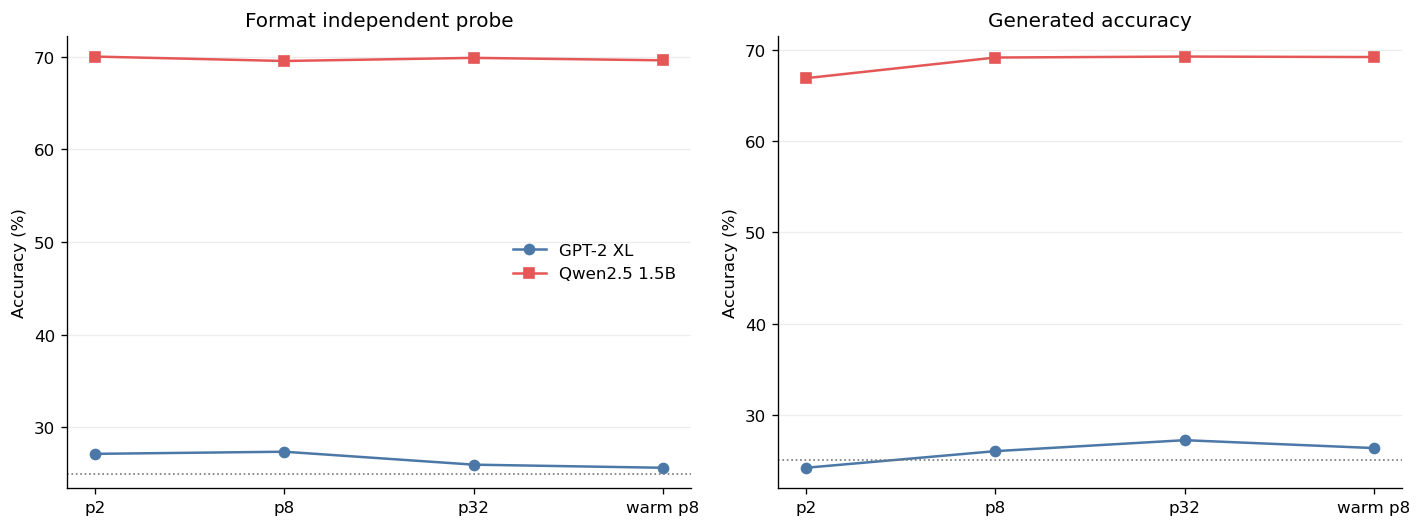

,model family,exposure,family,generated accuracy,probe accuracy,format compliance,extraction coverage
0,GPT-2 XL,p2,p2,0.2419,0.2712,0.8593,0.8593
1,GPT-2 XL,p8,p8,0.2601,0.2735,1.0000,1.0000
2,GPT-2 XL,p32,p32,0.2721,0.2596,1.0000,1.0000
3,GPT-2 XL,warm p8,wsft_p8,0.2634,0.2562,1.0000,1.0000
4,Qwen2.5 1.5B,p2,p2,0.6690,0.7003,0.9920,0.9981
5,Qwen2.5 1.5B,p8,p8,0.6916,0.6955,0.9988,1.0000
6,Qwen2.5 1.5B,p32,p32,0.6927,0.6989,0.9970,1.0000
7,Qwen2.5 1.5B,warm p8,wsft_p8,0.6921,0.6962,1.0000,1.0000


In [7]:
qwen_rows = []
for family, pattern in QWEN_TAGS.items():
    for seed in SEEDS:
        tag = pattern.format(seed=seed)
        result_dir = RESULTS / tag
        manifest_path = result_dir / 'manifest.json'
        assert manifest_path.exists()
        generated = read_rows(result_dir / 'sft_preds.jsonl')
        probe = read_rows(result_dir / 'sft_logprob_preds.jsonl')
        aligned(generated, probe)
        eval_metrics = read_json(result_dir / 'sft_eval.json')
        qwen_rows.append({
            'family': family, 'seed': seed,
            'generated accuracy': accuracy(generated),
            'probe accuracy': accuracy(probe),
            'format compliance': eval_metrics['format_compliance'],
            'extraction coverage': coverage(generated),
        })
        source_hashes[tag] = sha256(str(manifest_path))
qwen_df = pd.DataFrame(qwen_rows)

context_rows = []
for model_family, frame in (('GPT-2 XL', endpoint_df[endpoint_df.family != 'base']),
                            ('Qwen2.5 1.5B', qwen_df)):
    for family in FAMILIES:
        values = frame[frame.family == family]
        context_rows.append({
            'model family': model_family,
            'exposure': FAMILIES[family]['label'],
            'family': family,
            'generated accuracy': values['generated accuracy'].mean(),
            'probe accuracy': values['probe accuracy'].mean(),
            'format compliance': values['format compliance'].mean(),
            'extraction coverage': values['extraction coverage'].mean(),
        })
context_df = pd.DataFrame(context_rows)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)
for ax, metric, title in (
    (axes[0], 'probe accuracy', 'Format independent probe'),
    (axes[1], 'generated accuracy', 'Generated accuracy'),
):
    for model_family, colour, marker in (
        ('GPT-2 XL', '#4C78A8', 'o'), ('Qwen2.5 1.5B', '#E45756', 's')):
        frame = context_df[context_df['model family'] == model_family]
        x = np.arange(len(frame))
        ax.plot(x, frame[metric] * 100, marker=marker, color=colour,
                label=model_family)
    ax.axhline(25, color='#777777', linestyle=':', linewidth=1)
    ax.set_xticks(range(4), ['p2', 'p8', 'p32', 'warm p8'])
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.22)
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig05_gpt2_qwen_context.png', bbox_inches='tight')
plt.show()
display(context_df.style.format(precision=4))

## Base GRPO terminal outcome

All 3 direct base GRPO seeds stopped at the same registered A1 check. This is a reproducible recipe viability result. It is not an endpoint accuracy result and 3 seeds are excluded from F4 inference.

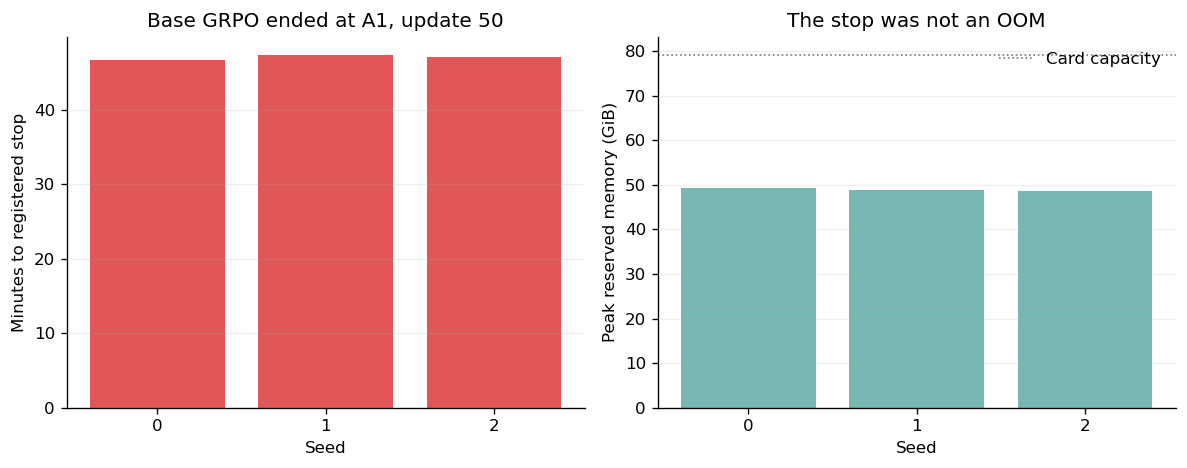

,seed,outcome,decision update,wall minutes,peak reserved GiB,OOM
0,0,A1 truncation stop,50,46.66,49.39,False
1,1,A1 truncation stop,50,47.44,48.92,False
2,2,A1 truncation stop,50,47.16,48.66,False


In [8]:
a1_df = pd.DataFrame(a1_rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(a1_df.seed.astype(str), a1_df['wall minutes'], color='#E15759')
axes[0].set_xlabel('Seed')
axes[0].set_ylabel('Minutes to registered stop')
axes[0].set_title('Base GRPO ended at A1, update 50')
axes[1].bar(a1_df.seed.astype(str), a1_df['peak reserved GiB'], color='#76B7B2')
axes[1].axhline(79.25, color='#777777', linestyle=':', linewidth=1,
                label='Card capacity')
axes[1].set_xlabel('Seed')
axes[1].set_ylabel('Peak reserved memory (GiB)')
axes[1].set_title('The stop was not an OOM')
axes[1].legend(frameon=False)
for ax in axes:
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
fig.savefig(FIG / 'fig06_base_grpo_a1.png', bbox_inches='tight')
plt.show()
display(a1_df.style.format(precision=2))

## Exact tables and machine readable summary

In [9]:
unit_rows = []
with open(RESULTS / 'colab_units.jsonl') as handle:
    for line in handle:
        row = json.loads(line)
        if str(row.get('notebook', '')).startswith('049_colab_gpt2_xl_'):
            unit_rows.append(row)

compute_rows = []
with open(RESULTS / 'compute_ledger.jsonl') as handle:
    for line in handle:
        row = json.loads(line)
        if str(row.get('run_tag', '')).startswith('049_'):
            compute_rows.append(row)
new_test_passes = int(sum(row.get('mmlu_test_passes', 0) for row in compute_rows))
assert new_test_passes == 24

endpoint_df.to_csv(FIG / '049_1_endpoint_seed_values.csv', index=False)
endpoint_summary.to_csv(FIG / '049_1_endpoint_summary.csv', index=False)
comparison_df.to_csv(FIG / '049_1_registered_probe_pairs.csv', index=False)
common_df.to_csv(FIG / '049_1_common_readings.csv', index=False)
guard_df.to_csv(FIG / '049_1_generated_guards.csv', index=False)
training_summary_df.to_csv(FIG / '049_1_training_summary.csv', index=False)
context_df.to_csv(FIG / '049_1_qwen_context.csv', index=False)
a1_df.to_csv(FIG / '049_1_base_grpo_a1.csv', index=False)

summary = {
    'completed': True,
    'experiment': '049',
    'scope': 'GPT-2 XL final symmetry package',
    'terminal_arms': 15,
    'committed_supervised_endpoints': 12,
    'base_grpo_a1_outcomes': 3,
    'new_mmlu_test_passes': new_test_passes,
    'initial_available_units': launch['initial_available_units'],
    'closing_available_units': 311.64,
    'net_compute_units': round(launch['initial_available_units'] - 311.64, 2),
    'primary_instrument': 'log probability answer probe',
    'endpoint_summary': json.loads(endpoint_summary.to_json(orient='records')),
    'registered_probe_pairs': json.loads(comparison_df.to_json(orient='records')),
    'common_readings': json.loads(common_df.to_json(orient='records')),
    'generated_guards': json.loads(guard_df.to_json(orient='records')),
    'base_grpo': {
        'formal_F4_allowed': False,
        'outcome': 'three of three seeds reached the exact A1 truncation stop',
        'records': json.loads(a1_df.to_json(orient='records')),
    },
    'conclusions': [
        'F1, F2a and F2b are inconclusive at every seed on the primary probe',
        'F3 has one corrected decline and two inconclusive seeds, so it has no common reading',
        'longer supervised exposure fits the training rows but does not produce a common probe gain',
        'direct base GRPO is not viable under the frozen 512 token recipe at any seed',
        'Qwen2.5 context is descriptive and must not be read as an isolated architecture effect',
    ],
    'source_record_sha256': source_hashes,
}
atomic_write_json(str(RESULTS / '049_family_summary.json'), summary)
print('wrote', RESULTS / '049_family_summary.json')
print('wrote figures and tables to', FIG)
print('net package compute units:', summary['net_compute_units'])
print('new MMLU test passes:', new_test_passes)

wrote /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/results/049_family_summary.json
wrote figures and tables to /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/049_1
net package compute units: 94.75
new MMLU test passes: 24


## Cross-referenced conclusion

049 pack finished successfully, but none of F1, F2a, F2b produced a common probe gain, decline or equivalence result. F3 has 1 corrected decline and 2 inconclusive seeds, so the family also has no common reading. p8 is the highest GPT-2 XL probe point, while p32 and the warm p8 start do not improve it.

Process evidence is clearer than the endpoint inference. All supervised schedules fitted their answer rows, p8 and later arms reached complete extraction, yet the GPT-2 XL probe stayed near four option chance. In separate Qwen2.5 1.5B context, the same exposure labels remain around 70% probe accuracy. This difference belongs to the whole pretrained model bundle and cannot be attributed to architecture alone.

Direct base GRPO didn't produce an endpoint. All 3 seeds reached the same A1 truncation stop at update 50 without OOM. So, the registered F4 comparison is unavailable, while the three seed stop supports a narrower conclusion that frozen direct base GRPO recipe is not reliable for GPT-2 XL.